In [1]:
import numpy as np
import pandas as pd
import random
import matplotlib.pyplot as plt
from scipy.integrate import quad
import math
from scipy.stats import norm

Aim: XVA charge model for a swap position or portfolio.

We seek to get our CVA, DVA and FVA charges for an underlying IRS swap. To achieve this first we need details on the swap as well default intensity assumptions for computing our XVA. We then simulate an Expected exposure profile for our swap. To do this we use a cox process and we model with a two factor Gaussian model. We also model our interest rate curve.  We showcase our exposure differences with and without a full variation margin. Initial margin calculations are quite complex and constitute a 99% 10-day VAR. However we use an approximation to showcase our initial margin as well. We then proceed with our XVA computations.

Now, we definea few helper functions for our model below to calculate constants or swap values

Some parameters that we have assumed.
Forward intensity curve : f(0,t) = a + b.t   ; a = 5 %, b = 0.2 %
Two factor model constants: sigma_r = 2 %, c = 40 %,  Kappa_2 = 5 % , rho_inf = 30 %



In [2]:
def v(c = 0.4, rho_inf = 0.3):                                                         #constant
    return np.sqrt(1 / c**2 - 1 - 2 * (rho_inf / c - 1) )

def rho_x(c = 0.4, rho_inf = 0.3):                                                     #constant - corr term of two factor model
    return (rho_inf / c - 1) / v(c, rho_inf)

def sigma_1(c = 0.4, sigma_r = 0.02):                                                  #constant - sigma term of two factor model
    return c * sigma_r

def sigma_2(c, rho_inf, sigma_r):                                                      ##constant - sigma term of two factor model
    return v(c, rho_inf) * sigma_1(c, sigma_r)

def x_helper_fun(t, c = 0.4, sigma_r = 0.02, rho_inf = 0.3, kappa_2 = 0.05):                           #constant - for closed form solution
    sigma1 = sigma_1(c, sigma_r)
    sigma2 = sigma_2(c, rho_inf, sigma_r)
    rhox = rho_x(c, rho_inf)
    return sigma1**2 * t + (rhox * sigma1 * sigma2)**2 * (np.exp(2 * kappa_2 * t) - 1) / (2 * kappa_2)

def y_helper_fun(t, c = 0.4, sigma_r = 0.02, rho_inf = 0.3, kappa_2 = 0.05):                           #constant - for closed form solution
    sigma1 = sigma_1(c, sigma_r)
    sigma2 = sigma_2(c, rho_inf, sigma_r)
    rhox = rho_x(c, rho_inf)
    return rhox * sigma1**2 * sigma2 * (np.exp(kappa_2 * t) - 1) / kappa_2 + rhox * sigma1 * sigma2**2 * (np.exp(2 * kappa_2 * t) - 1) / (2 * kappa_2)

def z_helper_fun(t, c = 0.4, sigma_r = 0.02, rho_inf = 0.3, kappa_2 = 0.05):                           #constant - for closed form solution
    sigma1 = sigma_1(c, sigma_r)
    sigma2 = sigma_2(c, rho_inf, sigma_r)
    rhox = rho_x(c, rho_inf)
    return (rhox * sigma1 * sigma2)**2 * (np.exp(2 * kappa_2 * t) - 1) / (2 * kappa_2) + sigma2**2 * (np.exp(2 * kappa_2 * t) - 1) / (2 * kappa_2)

def proba(p):
    return (norm.pdf(norm.ppf(p)) - norm.ppf(p) * (1 - p)) * (np.pi * 2)**0.5

function for simulation of X1 and x2 path x = {x1,x2} as part of our two factor model.

In [3]:
def x_paths(num_path=10, a = 0.05, b = 0.002, sigma_r = 0.02, c = 0.4, kappa_2 = 0.05, rho_inf = 0.3):
    num_steps = int(T / dt)
    sigma1 = sigma_1(c, sigma_r)
    sigma2 = sigma_2(c, rho_inf, sigma_r)
    rhox = rho_x(c, rho_inf)

    time_grid = [i * dt for i in range(num_steps + 1)]
    x_1_paths = np.zeros((num_path, num_steps + 1))
    x_2_paths = np.zeros((num_path, num_steps + 1))

    for i in range(num_path):

        x_1_paths[i, 0] = 0
        x_2_paths[i, 0] = 0

        for j in range(1, num_steps + 1):

            dW1 = np.random.normal(0, np.sqrt(dt))
            dW3 = np.random.normal(0, np.sqrt(dt))
            dW2 = rhox * dW1 + np.sqrt(1 - rhox**2) * dW3
            #preserving correlation between dW1 and dW2

            #finding the next x = previous x + dx, dx equation calculated in solutions
            x_1_paths[i,j] = x_1_paths[i,j - 1] + sigma1 * dW1 + dt * (x_helper_fun(time_grid[j], c, sigma_r, rho_inf, kappa_2) + y_helper_fun(time_grid[j], c, sigma_r, rho_inf, kappa_2) * np.exp(-kappa_2 * time_grid[j]))
            x_2_paths[i,j] = x_2_paths[i,j - 1] + sigma2 * dW2 + dt * (y_helper_fun(time_grid[j], c, sigma_r, rho_inf, kappa_2) * np.exp(-kappa_2 * time_grid[j]) + z_helper_fun(time_grid[j], c, sigma_r, rho_inf, kappa_2) * np.exp(-2 * kappa_2 * time_grid[j]) - kappa_2 * x_2_paths[i,j - 1])

    return x_1_paths, x_2_paths

In [4]:
def P_0_t(t, a = 0.05, b = 0.002):                                                  #discount function
    return np.exp(-(a * t + b * t ** 2 / 2))

def v_rec_0(h, notional = 50):                                                      #valuation function
    P_values = [P_0_t(t) for t in couponPeriods]
    return (sum(P_values[1:]) * dT * h + P_values[-1] - 1) * notional

def A_t_T(t, T = 10, c = 0.4, sigma_r = 0.02, rho_inf = 0.3, kappa_2 = 0.05):       #two factor model component
    tau = T - t
    A = tau ** 2 * x_helper_fun(t, c, sigma_r, rho_inf, kappa_2) / 2
    A += tau * (1 - np.exp(-kappa_2 * tau)) * np.exp(-kappa_2 * t) * y_helper_fun(t, c, sigma_r, rho_inf, kappa_2) / kappa_2
    A += (1-np.exp(-kappa_2 * tau))**2 * np.exp(-2*kappa_2*t) * z_helper_fun(t, c, sigma_r, rho_inf, kappa_2) / (2 * kappa_2**2)
    return A

def C_t_T(t, T, kappa_2 = 0.05):                                                    # two factor model component
    tau = T - t
    return [-tau, (np.exp(-kappa_2 * tau) - 1) / kappa_2]

def P_t_T(t, x_1, x_2, a = 0.05, b = 0.002, T = 10, c = 0.4, sigma_r = 0.02, rho_inf = 0.3, kappa_2 = 0.05):        #two factor
    C = C_t_T(t, T, kappa_2)
    return P_0_t(T, a, b) * np.exp(A_t_T(t, T, c, sigma_r, rho_inf, kappa_2) + C[0] * x_1 + C[1] * x_2) / P_0_t(t, a, b)

def r(t, x_1, x_2, a = 0.05, b = 0.002):                                                    #interest rate
    return a + b * t + x_1 + x_2

def beta_path(r_path, dt = 1/52):
    betas = [0] * len(r_path)
    betas[1:] = ((r_path[:(-1)] + r_path[1:]) * dt / 2)
    return np.exp(np.cumsum(betas))

def v_rec_t(t, x_1, x_2, beta_path, h, notional, dT, dt = 1/52):                          #valuataion function       notional = 50 dt = 1/2
    P_path = [P_t_T(t, x_1, x_2, T = T_i) for T_i in couponPeriods[math.ceil(2*t):]]
    beta_t = beta_path[int(t/dt)]
    beta_T_0 = beta_path[math.floor(int(t/dt)/20) * 20]
    return (h * dT * sum(P_path) + P_path[-1] - beta_t/beta_T_0) * notional

Below we take our swap inputs. For the demonstaration lets take Notional 50 million , 10 year semi annual coupon IRS swap with coupon x.

In [5]:
num_paths = 60                                                          #simulation paths
T = 10
dt = 1/52                                                               # weekly discretization
notional = 50
dT = 1/2                                                                #semiannual
num_steps = int(T/dt)
time_grid = [i * dt for i in range(num_steps + 1)]
couponPeriods = [i * dT for i in range(int (T/dT) + 1)]

Simulation

In [6]:
x_1_paths, x_2_paths = x_paths(num_path=num_paths)                        # generate our x = {x1,x2} for our two factor model

In [7]:
a = 0.05
r_paths = np.zeros((num_paths, num_steps + 1))                          # path for interest rate and Beta (discount function)
beta_paths = np.zeros((num_paths, num_steps + 1))
for i in range(num_paths):
    r_paths[i][0] = a
    for j in range(1, num_steps + 1):
        r_paths[i][j] = r(time_grid[j], x_1_paths[i][j], x_2_paths[i][j])
    beta_paths[i] = beta_path(r_paths[i])

In [8]:
h_values = [0.02, 0.04, 0.06, 0.08]                                                                             #varying coupon
V_rec = []
V_pay = []
notional = 50
dT = 1/2

for h in h_values:
    v_rec_paths = np.zeros((num_paths, num_steps + 1))
    v_pay_paths = np.zeros((num_paths, num_steps + 1))
    for i in range(num_paths):
        for j in range(num_steps + 1):
            vs = v_rec_t(time_grid[j], x_1_paths[i][j], x_2_paths[i][j], beta_paths[i], h, notional, dT, dt = dt)              # Swap Valuation
            if vs >= 0:
                v_rec_paths[i][j] = vs                                                                           #positive exposure towards receiver swap
            else:
                v_pay_paths[i][j] = -vs                                                                          #positive exposure towards payer swap

    V_rec.append(v_rec_paths)
    V_pay.append(v_pay_paths)

    EE_rec = [np.mean(v_rec_paths,axis = 0) for v_rec_paths in V_rec]
    EE_pay = [np.mean(v_pay_paths,axis = 0) for v_pay_paths in V_pay]

PVEE_rec = [np.mean(v_rec_paths/beta_paths,axis = 0) for v_rec_path in V_rec]                  #present value of expected exposures which we will use later
PVEE_pay = [np.mean(v_pay_paths/beta_paths,axis = 0) for v_pay_path in V_pay]                  #present value of expected exposures which we will use later

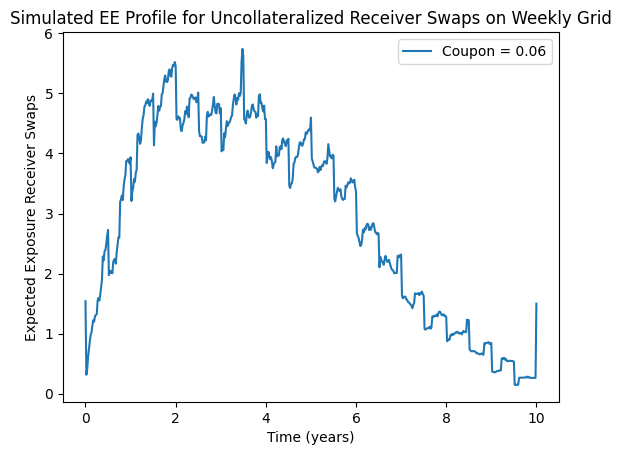

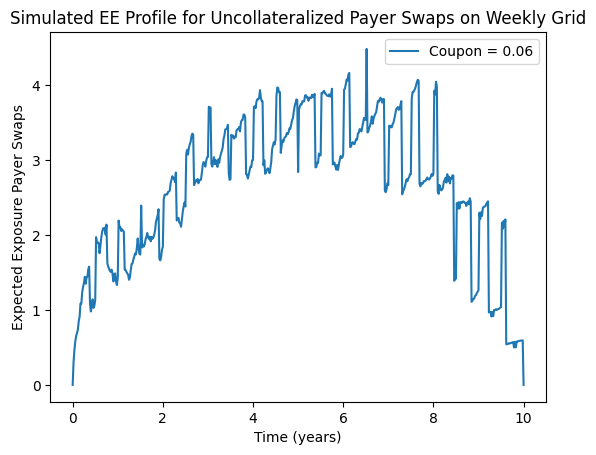

In [9]:
plt.plot(time_grid, EE_rec[2], label=f'Coupon = 0.06')
plt.xlabel('Time (years)')
plt.ylabel('Expected Exposure Receiver Swaps')
plt.legend()
plt.title("Simulated EE Profile for Uncollateralized Receiver Swaps on Weekly Grid")
plt.show()

plt.plot(time_grid,  EE_pay[2], label=f'Coupon = 0.06')
plt.xlabel('Time (years)')
plt.ylabel('Expected Exposure Payer Swaps')
plt.legend()
plt.title("Simulated EE Profile for Uncollateralized Payer Swaps on Weekly Grid")
plt.show()

What if we had full Variation margin and Initial Margin. How do our exposures change then?

In [10]:
h_values = [0.02, 0.04, 0.06, 0.08]
EE_rec_vm = []
EE_pay_vm = []
PVEE_rec_margin =[]
PVEE_pay_margin =[]
pm = proba(0.99)                                                                                                   # 99% interval IM multiplier.
notional = 50
dT = 1/2

for h in h_values:
    v_rec_paths = np.zeros((num_paths, num_steps + 1))
    v_pay_paths = np.zeros((num_paths, num_steps + 1))
    pv_rec_paths = np.zeros((num_paths, num_steps + 1))
    pv_pay_paths = np.zeros((num_paths, num_steps + 1))
    d=2                                                                                                              #MPOR

    for i in range(num_paths):
        for j in range(num_steps + 1):
            vs = v_rec_t(time_grid[j], x_1_paths[i][j], x_2_paths[i][j], beta_paths[i], h,notional, dT, dt = dt)
            if j<=d:
                vm = 0
            else:
                vs_lag = v_rec_t(time_grid[j], x_1_paths[i][j-d], x_2_paths[i][j-d], beta_paths[i], h,notional, dT,  dt = dt)
                vm = (vs - vs_lag) * pm                                                                              # v(t) - v(t-d)  (MPOR lag exposure) * IM multiplier.

            if vm >= 0:
                v_rec_paths[i][j] = vm
                pv_rec_paths[i][j] = vm/beta_paths[i][j]                               #for PV

            else:
                v_pay_paths[i][j] = -vm
                pv_pay_paths[i][j] = -vm/beta_paths[i][j]                              #for PV
    E_v_rec = np.mean(v_rec_paths,axis = 0)
    E_v_pay = np.mean(v_pay_paths,axis = 0)

    PV_rec = np.mean(pv_rec_paths, axis = 0)
    PV_pay = np.mean(pv_pay_paths, axis = 0)

    EE_rec_vm.append(E_v_rec)
    EE_pay_vm.append(E_v_pay)

    PVEE_rec_margin.append(PV_rec)
    PVEE_pay_margin.append(PV_pay)


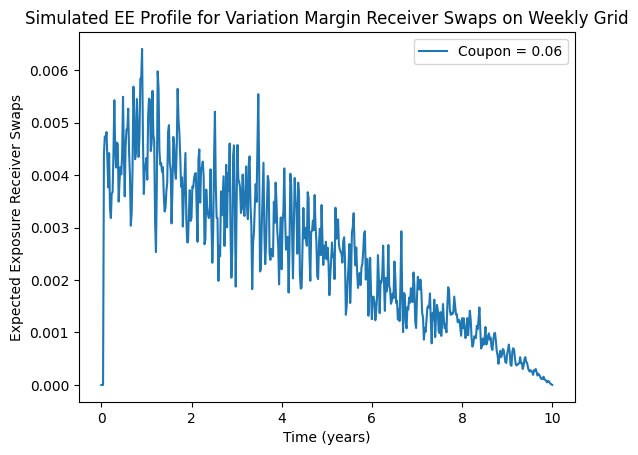

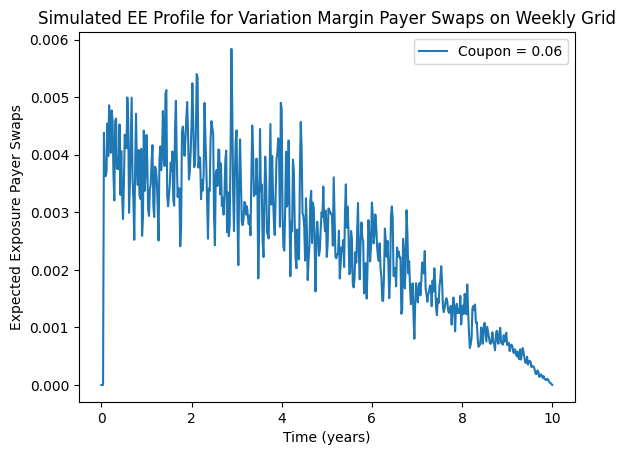

In [11]:
plt.plot(time_grid,EE_rec_vm[2], label=f'Coupon = 0.06')
plt.xlabel('Time (years)')
plt.ylabel('Expected Exposure Receiver Swaps')
plt.legend()
plt.title("Simulated EE Profile for Variation Margin Receiver Swaps on Weekly Grid")
plt.show()

plt.plot(time_grid, EE_pay_vm[2], label=f'Coupon = 0.06')
plt.xlabel('Time (years)')
plt.ylabel('Expected Exposure Payer Swaps')
plt.legend()
plt.title("Simulated EE Profile for Variation Margin Payer Swaps on Weekly Grid")
plt.show()

Now We have completed simulating our exposure profiles. We now jump into our XVA. For this we need to assume default intensities to proceed further. Lets say we are the Bank B and we are trading with Client A. We will compute for both trades. Default intensity of bank is 2.5% whereas for client is 4%. So from our perspective(Bank) we get our XVA for both trades i.e if we were in a receiver swap or a payer swap. Note: We are using MPOR lag of 0.5 months i,e 2 weeks

In [12]:
s_B = 0.015                                                                 #assumed spread of our bank
lambda_A = 0.04
lambda_B = 0.025
R = 0.4                                                                          #recovery rate

X_A = np.array([np.exp(-lambda_A * t) for t in time_grid])                       #intensities
X_B = [np.exp(-lambda_B * t) for t in time_grid]                                 # intensities
X2_A = [np.exp(-lambda_A * t) for t in time_grid]
X2_B = np.array([np.exp(-lambda_B * t) for t in time_grid])

In [13]:
def CVA_Bi(R, PVEE, X_A, X_B):
    dX_A = np.zeros(num_steps + 1)
    dX_A[1:] = list(X_A[1:] - X_A[:(-1)])
    return (R - 1) * sum(PVEE*X_B*dX_A)

def DVA_bi(R, PVEE, X_A, X_B):
    dX_B = np.zeros(num_steps + 1)
    dX_B[1:] = list(X_B[1:] - X_B[:(-1)])
    return (R - 1) * sum(PVEE*X_A*dX_B)

In [14]:
CVA_pay = CVA_Bi(R, PVEE_pay[2], X_A, X_B) * 1000000
CVA_rec = CVA_Bi(R, PVEE_rec[2], X_A, X_B)* 1000000
CVA_rec_margin = CVA_Bi(R, PVEE_rec_margin[2], X_A, X_B)* 1000000
CVA_pay_margin = CVA_Bi(R, PVEE_pay_margin[2], X_A, X_B)* 1000000

DVA_pay = DVA_bi(R, PVEE_pay[2], X2_A, X2_B) * 1000000
DVA_rec = DVA_bi(R, PVEE_rec[2], X2_A, X2_B)* 1000000
DVA_rec_margin = DVA_bi(R, PVEE_rec_margin[2], X2_A, X2_B)* 1000000
DVA_pay_margin = DVA_bi(R, PVEE_pay_margin[2], X2_A, X2_B)* 1000000

FVA for fully margined collateralized swaps is zero. We will compute FVA for the uncollateralized swap. MVA is associated with Inital margin so it will be for the fully collateralized swap.

In [15]:
FVA_rec = []
for i in range(len(h_values)):
    intergrate_terms= np.zeros((num_paths, num_steps + 1))
    for j in range(num_paths):
        intergrate_terms[j] = s_B * (V_rec[i][j] - V_pay[i][j]) * X_B / beta_paths[j]
    E_intergrate_terms = np.mean(intergrate_terms, axis = 0)
    fva = (sum(E_intergrate_terms[1:]) + sum(E_intergrate_terms[:(-1)])) * dt /2
    FVA_rec.append(fva)

In [16]:
FVA_pay = []
for i in range(len(h_values)):
    intergrate_terms= np.zeros((num_paths, num_steps + 1))
    for j in range(num_paths):
        intergrate_terms[j] = s_B * (V_pay[i][j] - V_rec[i][j]) * X_B / beta_paths[j]
    E_intergrate_terms = np.mean(intergrate_terms, axis = 0)
    fva = (sum(E_intergrate_terms[1:]) + sum(E_intergrate_terms[:(-1)])) * dt /2
    FVA_pay.append(fva)

In [17]:
FVA_pay = FVA_pay[2] *1000000
FVA_rec = FVA_rec[2] *1000000

Negative FVA can be interpreted as a funding benefit: an excess amount of cash that can be used to retire already
outstanding “expensive” debt. Some FVAs are negative since thses FCAs are smaller than FBAs. This is the case if B is short derivative assets, and is therefore in the aggregate receiving funding from its counterparties

In [18]:
def MVA(R, PVEE, X_B):
    dX_B = np.zeros(num_steps + 1)
    dX_B[1:] = list(X_B[1:] - X_B[:(-1)])
    return 5.8* (R - 1) * sum(PVEE*dX_B)

In [19]:
mva_pay_margin = MVA(R,PVEE_pay_margin[2], X2_B) * 1000000
mva_rec_margin = MVA(R,PVEE_rec_margin[2], X2_B) * 1000000

In [20]:
swap_list = ['Payer Swap', 'Receiver Swap', 'Margin Payer Swap', 'Margin Receiver Swap']
MVA_values = [0,0,mva_pay_margin, mva_rec_margin]
CVA_Values = [CVA_pay, CVA_rec, CVA_pay_margin, CVA_rec_margin]
DVA_Values = [DVA_pay, DVA_rec, DVA_pay_margin, DVA_rec_margin]
FVA_values = [FVA_pay, FVA_rec, 0,0]

In [21]:
# Creating a DataFrame
XVA_results = pd.DataFrame({ 'Swap Type': swap_list, 'CVA': CVA_Values, 'DVA': DVA_Values, 'FVA':FVA_values, 'MVA': MVA_values })


1) not accounting for mva leads to underpricing of risk 2) shareholder value preservation though accounting for the margin risk, liquidity risk through mva
3) CVa drops with collateral

In [22]:
XVA_results

,Swap Type,CVA,DVA,FVA,MVA
0,Payer Swap,1.327225e+05,82939.584679,-122676.760432,0.000000
1,Receiver Swap,1.039802e+06,649782.496985,122676.760432,0.000000
2,Margin Payer Swap,4.095403e+02,255.925798,0.000000,1684.514109
3,Margin Receiver Swap,4.140582e+02,258.749051,0.000000,1690.413067
